# 02 — Atari Pong: when the observation is pixels

<div><span style="display:inline-block;background:#17BECF;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">OBSERVATION</span><span style="display:inline-block;background:#1F3A93;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">REPRESENTATION</span><span style="display:inline-block;background:#0F766E;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">POLICY</span><span style="display:inline-block;background:#F58518;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ACTION</span><span style="display:inline-block;background:#8C564B;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">HISTORY</span><span style="display:inline-block;background:#4C78A8;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">STATE</span><span style="display:inline-block;background:#334155;color:white;font-weight:800;padding:4px 8px;border-radius:5px;margin:3px">ENVIRONMENT</span></div>

Now stop giving the agent `ball_x` and `ball_velocity`.

Give it an image.

The policy needs some mechanism to turn pixels into useful internal features.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-020" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Atari-style agent</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">PIXELS</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-020)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">VISUAL ENCODER</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-020)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LATENT FEATURES</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-020)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#0F766E" stroke="#0F766E" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">POLICY</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-020)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#F58518" stroke="#F58518" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ACTION</text>
</svg>
</div>


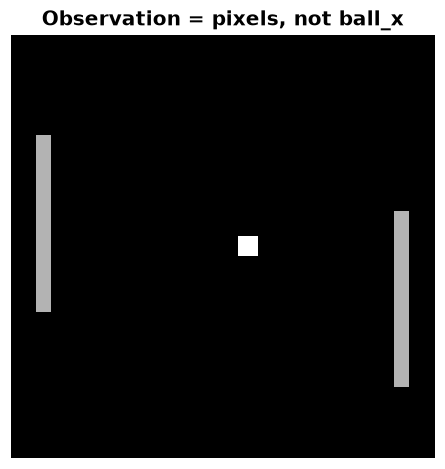

In [1]:
from pathlib import Path
import sys, numpy as np, matplotlib.pyplot as plt
repo = Path.cwd()
if repo.name == "notebooks": repo = repo.parent
sys.path.insert(0, str(repo))
from visuals import COLORS

# Synthetic Atari-like frame: lightweight and requires no emulator.
frame = np.zeros((84,84))
frame[20:55, 5:8] = 0.7
frame[35:70, 76:79] = 0.7
frame[40:44, 45:49] = 1.0

plt.figure(figsize=(5,5))
plt.imshow(frame, cmap="gray")
plt.axis("off")
plt.title("Observation = pixels, not ball_x")
plt.show()

<div style="border-left:10px solid #17BECF;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#17BECF">OBSERVATION</div><div style="font-size:21px;font-weight:800;margin-top:4px">1. Pixels are observations, not automatically state</div></div>

The image contains useful facts, but not in a convenient symbolic format.

A neural visual encoder can learn features that support action selection.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-022" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Learned representation</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">84×84 PIXELS</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-022)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">CNN / ENCODER</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-022)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#1F3A93" stroke="#1F3A93" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">FEATURE VECTOR</text>
</svg>
</div>


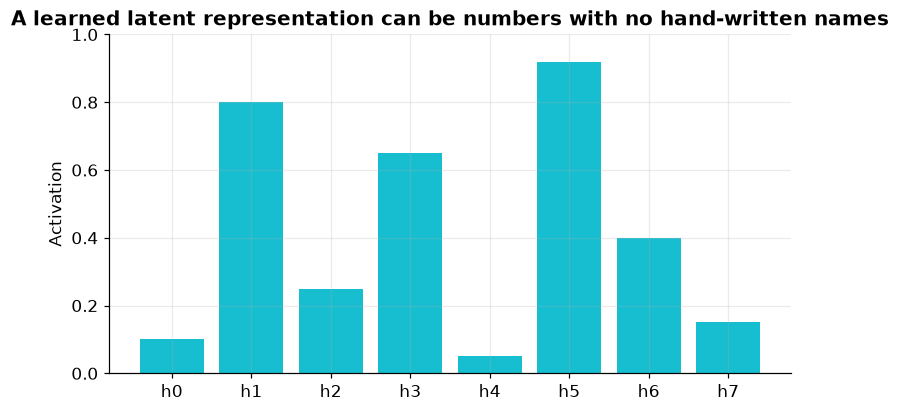

In [2]:
# Conceptual learned feature activations.
features = np.array([0.1,0.8,0.25,0.65,0.05,0.92,0.4,0.15])
plt.figure(figsize=(8,4))
plt.bar([f"h{i}" for i in range(len(features))], features, color=COLORS["OBSERVATION"])
plt.ylim(0,1)
plt.ylabel("Activation")
plt.title("A learned latent representation can be numbers with no hand-written names")
plt.show()

<div style="border-left:10px solid #8C564B;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#8C564B">HISTORY</div><div style="font-size:21px;font-weight:800;margin-top:4px">2. One frame can hide motion</div></div>

A single picture can show *where* the ball is but not always *which direction* it is moving.

Frame stacking is one cheap way to inject recent history.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-024" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">History repairs missing information</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">FRAME t-3</text>
<line x1="180.0" y1="82" x2="197.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-024)"/>
<rect x="205.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="280.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">FRAME t-2</text>
<line x1="360.0" y1="82" x2="377.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-024)"/>
<rect x="385.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="460.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">FRAME t-1</text>
<line x1="540.0" y1="82" x2="557.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-024)"/>
<rect x="565.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="640.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">FRAME t</text>
<line x1="720.0" y1="82" x2="737.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-024)"/>
<rect x="745.0" y="55" rx="12" width="150.0" height="55" fill="#64748B" stroke="#64748B" stroke-width="2"/><text x="820.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">MOTION INFERABLE</text>
</svg>
</div>


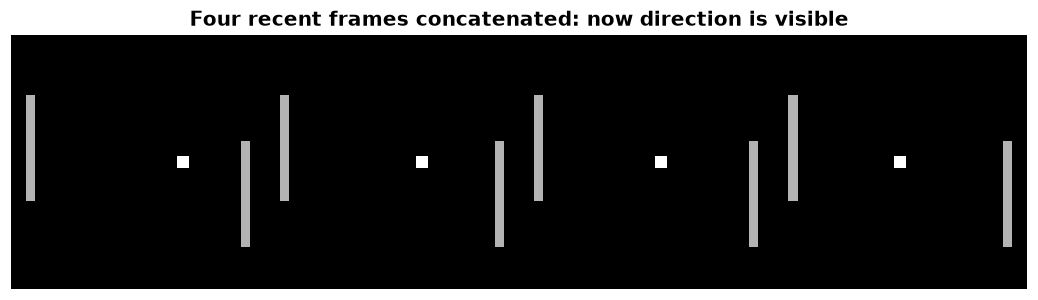

In [3]:
canvas = np.zeros((84, 84*4))
for i, x in enumerate([55,50,45,40]):
    f = np.zeros((84,84))
    f[20:55,5:8] = 0.7
    f[35:70,76:79] = 0.7
    f[40:44,x:x+4] = 1.0
    canvas[:, i*84:(i+1)*84] = f

plt.figure(figsize=(12,3))
plt.imshow(canvas, cmap="gray")
plt.axis("off")
plt.title("Four recent frames concatenated: now direction is visible")
plt.show()

<div style="border-left:10px solid #17BECF;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#17BECF">OBSERVATION</div><div style="font-size:21px;font-weight:800;margin-top:4px">3. This is already a POMDP-flavored issue</div></div>

If the latest observation is insufficient, the agent needs history or memory.

That is the bridge from ordinary MDP intuition toward partial observability.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-026" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Why memory appears</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">LATEST OBS</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-026)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#8C564B" stroke="#8C564B" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">HISTORY / MEMORY</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-026)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#4C78A8" stroke="#4C78A8" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">BETTER INTERNAL STATE</text>
</svg>
</div>


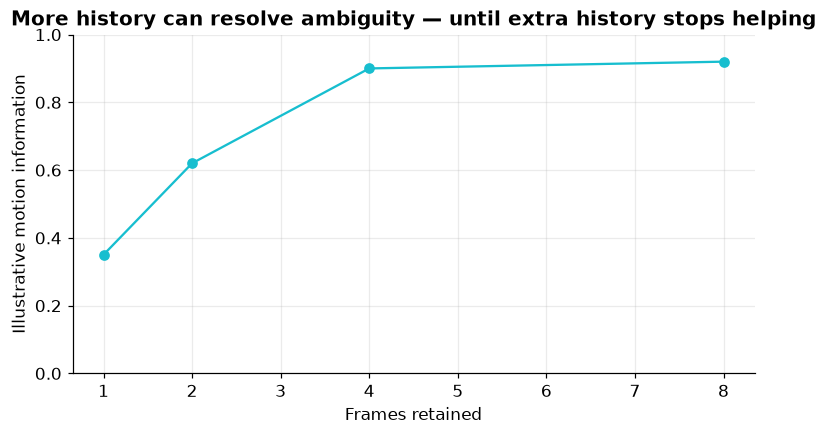

In [4]:
history_lengths = [1,2,4,8]
illustrative_motion_info = [0.35,0.62,0.90,0.92]

plt.figure(figsize=(8,4))
plt.plot(history_lengths, illustrative_motion_info, marker="o", color=COLORS["OBSERVATION"])
plt.xlabel("Frames retained")
plt.ylabel("Illustrative motion information")
plt.ylim(0,1)
plt.title("More history can resolve ambiguity — until extra history stops helping")
plt.show()

<div style="border-left:10px solid #334155;background:#16181c;color:#f4f4f5;padding:14px 18px;border-radius:9px;margin:10px 0 14px 0"><div style="font-size:12px;font-weight:900;letter-spacing:.12em;color:#334155">ENVIRONMENT</div><div style="font-size:21px;font-weight:800;margin-top:4px">4. Why Atari is optional for you right now</div></div>

You do **not** need a real Atari emulator to understand the research question.

Elder Mist gives us a cleaner controlled environment where we know the true hidden variables and can deliberately hide them.

<div style="margin:12px 0">
<svg width="100%" viewBox="0 0 900 150" role="img">
<defs><marker id="arrow-028" markerWidth="8" markerHeight="8" refX="7" refY="4" orient="auto"><path d="M0,0 L8,4 L0,8 z" fill="#334155"/></marker></defs>
<rect x="1" y="1" width="898" height="148" rx="12" fill="white" stroke="#E5E7EB"/>
<text x="450.0" y="30" text-anchor="middle" font-size="20" font-weight="bold" fill="#111827">Use the simplest environment that teaches the concept</text>
<rect x="25.0" y="55" rx="12" width="150.0" height="55" fill="#17BECF" stroke="#17BECF" stroke-width="2"/><text x="100.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ATARI PIXELS</text>
<line x1="180.0" y1="82" x2="317.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-028)"/>
<rect x="325.0" y="55" rx="12" width="150.0" height="55" fill="#64748B" stroke="#64748B" stroke-width="2"/><text x="400.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">SAME RL IDEAS</text>
<line x1="480.0" y1="82" x2="617.0" y2="82" stroke="#334155" stroke-width="2" marker-end="url(#arrow-028)"/>
<rect x="625.0" y="55" rx="12" width="150.0" height="55" fill="#334155" stroke="#334155" stroke-width="2"/><text x="700.0" y="88" text-anchor="middle" font-size="14" font-weight="bold" fill="white">ELDER MIST CONTROLLED LAB</text>
</svg>
</div>
